# Week 4: t-Test & Effect Sizes

**Contents**

0. Setup and data (the new `oasis_cross-sectional_MR1.csv`)
1. Hypothesis testing: H0, H1, α and β errors
2. How do we get the p-value? The distribution of differences under H0
3. Three kinds of t-test: independent, dependent, single group
4. Assumptions: Q-Q plot, formal tests of normality, equal variances
5. Statistical power
6. Effect sizes: why a p-value is not enough, Cohen's d, η² and ω²
7. Reporting and a caution about the word "significant"
8. Summary

## 0. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)          # seed: results are reproducible

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25})
C1, C2, GREY = "#0072B2", "#D55E00", "#6b6b6b"   # colour-blind-safe blue / orange

From this week on we load a file that contains **only the first session (`MR1`) of every subject**. That means one row per person, so the rows are independent and we no longer need to filter out `MR2` ourselves. It also means that **there are no repeated measures in the file**, which matters for the dependent t-test (section 3.2).

In [3]:
df = pd.read_csv("oasis_cross-sectional_MR1.csv")
print(df.shape)
print("IDs ending in MR1:", df["ID"].str.endswith("MR1").all())
df.head()

(416, 12)
IDs ending in MR1: True


,ID,M_F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


We work with two columns this week:

* `eTIV`: estimated total intracranial volume (head size). Men have larger heads on average, so this is a **large** effect.
* `Age`: age in years. The sex difference is small, so this is a **small** effect.

Having one big and one small effect side by side is useful for power and effect sizes later.

In [5]:
men_etiv   = df.loc[df["M_F"] == "M", "eTIV"].to_numpy(float)
women_etiv = df.loc[df["M_F"] == "F", "eTIV"].to_numpy(float)
men_age    = df.loc[df["M_F"] == "M", "Age"].to_numpy(float)
women_age  = df.loc[df["M_F"] == "F", "Age"].to_numpy(float)

summary = pd.DataFrame({
    "n":    [len(men_etiv), len(women_etiv)],
    "eTIV mean": [men_etiv.mean(), women_etiv.mean()],
    "eTIV SD":   [men_etiv.std(ddof=1), women_etiv.std(ddof=1)],
    "Age mean":  [men_age.mean(), women_age.mean()],
    "Age SD":    [men_age.std(ddof=1), women_age.std(ddof=1)],
}, index=["men", "women"]).round(1)
summary

,n,eTIV mean,eTIV SD,Age mean,Age SD
men,160,1592.0,135.2,49.3,25.1
women,256,1410.9,129.4,54.8,24.9


## 1. Hypothesis testing

A hypothesis test starts from two competing statements about the population:

* **H0 (null hypothesis):** there is no difference (for two groups: μ₁ = μ₂).
* **H1 (alternative hypothesis):** there is a difference.
  * *undirected*: μ₁ ≠ μ₂ (two-sided test)
  * *directed*: μ₁ > μ₂ or μ₁ < μ₂ (one-sided test). The direction must be decided **before** looking at the data.

We assume H0 is true and ask: *how likely are data at least this extreme if there really were no difference?* That probability is the **p-value**. If it is smaller than the significance level **α** (conventionally .05), we reject H0.

Since we decide on the basis of a sample, we can be wrong in two ways:

| | **H0 is true** (no effect) | **H1 is true** (real effect) |
|---|---|---|
| **We keep H0** | correct decision (1 − α) | **β error** (type II): we miss a real effect |
| **We reject H0** | **α error** (type I): false alarm | correct decision, **power** (1 − β) |

We cannot see the truth in real data, but in a simulation we can choose it. Here we run 10,000 experiments with n = 30 per group, once with **no** true difference and once with a true difference of half a standard deviation (d = 0.5).

In [50]:
def sim_rejection_rate(d, n=30, reps=10_000, alpha=.05):
    """Share of simulated experiments with p < alpha. d = true difference in SD units."""
    a = rng.normal(0, 1, (n, reps))
    b = rng.normal(d, 1, (n, reps))
    p = stats.ttest_ind(a, b).pvalue
    return (p < alpha).mean()

alpha_rate = sim_rejection_rate(d=0.0)
power_rate = sim_rejection_rate(d=0.5)

table = pd.DataFrame({"H0 true (d = 0)": [1 - alpha_rate, alpha_rate],
                      "H1 true (d = 0.5)": [1 - power_rate, power_rate]},
                     index=["keep H0", "reject H0"]).round(3)
print(table)
print(f"\nα error rate: {alpha_rate:.3f}   β error rate: {1 - power_rate:.3f}   power: {power_rate:.3f}")

           H0 true (d = 0)  H1 true (d = 0.5)
keep H0              0.952              0.522
reject H0            0.048              0.478

α error rate: 0.048   β error rate: 0.522   power: 0.478


Reading the table:

* In the left column, nothing is going on, and we still reject H0 in about 5% of the experiments. That is exactly what α = .05 *means*: we accept a 5% false alarm rate.
* In the right column, there *is* a real effect, but with only 30 per group we miss it in a large share of the experiments (that share is β). The power is therefore well below the 80% that is usually aimed for. We come back to this in section 5.

## 2. How do we get the p-value?

The idea from the slides in four steps:

1. Draw two samples and compute the **difference of the means**, D = x̄₁ − x̄₂.
2. If H0 is true, D varies around 0 from sample to sample (sampling distribution of the difference).
3. Standardize: **t = D / SE(D)**, where the standard error uses the pooled standard deviation.
4. Compare t with the **t distribution** with df = n₁ + n₂ − 2 degrees of freedom. The p-value is the share of that distribution at least as extreme as our t.

### 2.1 The distribution of D under H0, built by shuffling

For this we use `Age` by sex, because the sex difference in age is small, so shuffling the labels is a fair picture of "H0 is true". (For `eTIV` the true difference is large, so shuffled data would be a poor picture of H0.)

If H0 is true, the labels "M" and "F" mean nothing. So we shuffle them many times and compute D every time.

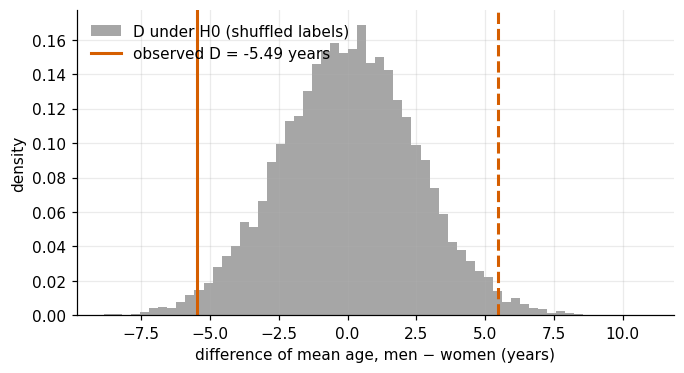

Share of shuffles at least as extreme as the observed D (two-sided): 0.028


In [29]:
age_all = np.concatenate([men_age, women_age])
n1, n2 = len(men_age), len(women_age)
D_obs = men_age.mean() - women_age.mean()

D_null = np.empty(10_000)
for i in range(D_null.size):
    perm = rng.permutation(age_all)
    D_null[i] = perm[:n1].mean() - perm[n1:].mean()

p_perm = (np.abs(D_null) >= abs(D_obs)).mean()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(D_null, bins=60, color=GREY, alpha=.6, density=True, label="D under H0 (shuffled labels)")
ax.axvline(D_obs, color=C2, lw=2, label=f"observed D = {D_obs:.2f} years")
ax.axvline(-D_obs, color=C2, lw=2, ls="--")
ax.set_xlabel("difference of mean age, men − women (years)")
ax.set_ylabel("density")
ax.legend(frameon=False, loc="upper left")
plt.show()
print(f"Share of shuffles at least as extreme as the observed D (two-sided): {p_perm:.3f}")

The shuffled differences form a bell shape around 0. The dashed line mirrors the observed difference, because for an **undirected** test we count extremes on both sides. The share of shuffles beyond the two lines is a p-value, found without any formula.

### 2.2 The same thing with the t distribution

Now the formula route: pooled SD → standard error → t → p from the t distribution. We do it by hand first and compare it with `scipy`.

In [30]:
def pooled_sd(a, b):
    n1, n2 = len(a), len(b)
    return np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))

sp   = pooled_sd(men_age, women_age)
se   = sp * np.sqrt(1 / n1 + 1 / n2)
t    = D_obs / se
dof  = n1 + n2 - 2
p_t  = 2 * stats.t.sf(abs(t), dof)          # two-sided: both tails

res = stats.ttest_ind(men_age, women_age)    # equal variances assumed (the classic t-test)
print(f"by hand : t({dof}) = {t:.3f}, p = {p_t:.3f}")
print(f"scipy   : t({dof:.0f}) = {res.statistic:.3f}, p = {res.pvalue:.3f}")

by hand : t(414) = -2.181, p = 0.030
scipy   : t(414) = -2.181, p = 0.030


Both routes agree with each other, and the p-value of the shuffling route (2.1) is close to it as well.

### 2.3 The t distribution and the critical value

The t distribution looks like a normal distribution, but has heavier tails when df is small. With growing df it converges to the normal distribution.

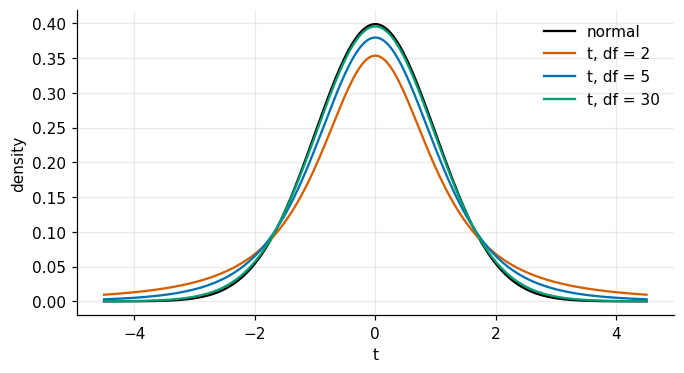

In [ ]:
x = np.linspace(-4.5, 4.5, 400)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(x, stats.norm.pdf(x), color="black", lw=1.5, label="normal")
for df_, col in [(2, C2), (5, C1), (30, "#009E73")]:
    ax.plot(x, stats.t.pdf(x, df_), color=col, lw=1.5, label=f"t, df = {df_}")
ax.set_xlabel("t")
ax.set_ylabel("density")
ax.legend(frameon=False)
plt.show()

The **critical value** t_crit is the t that cuts off the share α in the tail(s):

* directed test: α in **one** tail, so t_crit = `t.ppf(1 − α, df)`
* undirected test: α/2 in **each** tail, so t_crit = `t.ppf(1 − α/2, df)`

The same α gives a *smaller* critical value for the directed test, so it rejects H0 more easily. That is why the direction must be fixed before looking at the data.

In [32]:
rows = []
for df_ in [5, 10, 30, 100, 414]:
    rows.append({"df": df_,
                 "directed (α = .05)":   stats.t.ppf(1 - .05, df_),
                 "undirected (α = .05)": stats.t.ppf(1 - .05 / 2, df_)})
rows.append({"df": "normal (∞)", "directed (α = .05)": stats.norm.ppf(.95),
             "undirected (α = .05)": stats.norm.ppf(.975)})
pd.DataFrame(rows).round(3).set_index("df")

,directed (α = .05),undirected (α = .05)
df,,
5,2.015,2.571
10,1.812,2.228
30,1.697,2.042
100,1.660,1.984
414,1.649,1.966
normal (∞),1.645,1.960


## 3. Three kinds of t-test

| Type | Question | Example in this notebook |
|---|---|---|
| **independent** (two groups) | do two *different* groups differ? | head size (`eTIV`) of men vs. women (data) |
| **dependent / paired** | do the *same* people differ between two conditions? | depression score before vs. after treatment (slides) |
| **single group** | does one group differ from a *given* value? | mean `eTIV` vs. a reference value (data) |

### 3.1 Independent samples: eTIV of men vs. women

**Hypotheses:** H0: μ(men) = μ(women); H1: μ(men) ≠ μ(women) (undirected).

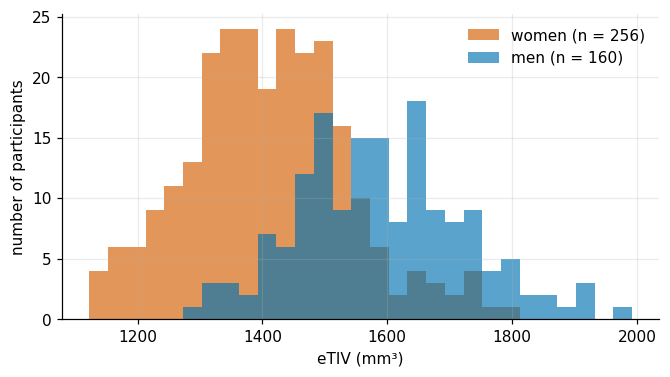

classic t-test: t(414) = 13.65, p = 2.8e-35
Welch t-test  : t(326.5) = 13.51, p = 2.4e-33
mean difference (men − women): 181 mm³


In [33]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(df["eTIV"].min(), df["eTIV"].max(), 30)
ax.hist(women_etiv, bins=bins, color=C2, alpha=.65, label=f"women (n = {len(women_etiv)})")
ax.hist(men_etiv,   bins=bins, color=C1, alpha=.65, label=f"men (n = {len(men_etiv)})")
ax.set_xlabel("eTIV (mm³)")
ax.set_ylabel("number of participants")
ax.legend(frameon=False)
plt.show()

res = stats.ttest_ind(men_etiv, women_etiv)                       # equal variances assumed
res_welch = stats.ttest_ind(men_etiv, women_etiv, equal_var=False) # Welch: no equal-variance assumption
dof = len(men_etiv) + len(women_etiv) - 2
print(f"classic t-test: t({dof}) = {res.statistic:.2f}, p = {res.pvalue:.2g}")
print(f"Welch t-test  : t({res_welch.df:.1f}) = {res_welch.statistic:.2f}, p = {res_welch.pvalue:.2g}")
print(f"mean difference (men − women): {men_etiv.mean() - women_etiv.mean():.0f} mm³")

Men have a clearly larger mean `eTIV`, the p-value is tiny, and we reject H0. Whether the classic or the Welch version is used makes almost no difference here. In section 4 we look at when it does.

**Directed version.** Suppose that, *before* looking at the data, we had predicted that men have the larger head. The alternative is then "men > women" and `scipy` takes `alternative="greater"`:

In [34]:
res_dir = stats.ttest_ind(men_etiv, women_etiv, alternative="greater")
print(f"directed (men > women): t = {res_dir.statistic:.2f}, p = {res_dir.pvalue:.2g}")
print("p(directed) = p(undirected)/2 when the effect points in the predicted direction:",
      np.isclose(res_dir.pvalue, res.pvalue / 2))

directed (men > women): t = 13.65, p = 1.4e-35
p(directed) = p(undirected)/2 when the effect points in the predicted direction: True


### 3.2 Dependent samples: before and after treatment (example from the slides)

The MR1 file contains each person only once, so there are no repeated measurements in the data. For the dependent t-test we therefore use the situation from the slides: the same patients measured **before and after a treatment**. The numbers below are **simulated** (and not OASIS data), only to show the mechanics.

**Idea:** a paired t-test is a **single-group t-test on the differences**. Each person is their own control, so the differences between people drop out of the comparison.

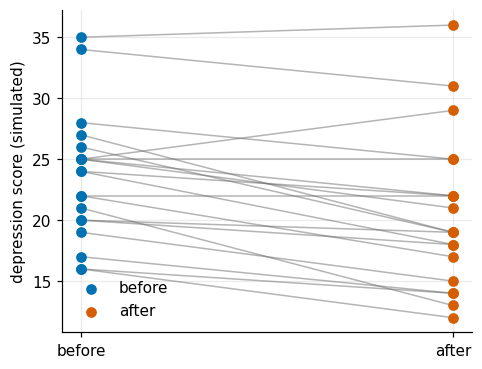

paired t-test         : t(19) = 4.46, p = 0.00027
one-sample t on diffs : t(19) = 4.46, p = 0.00027   (identical)
wrongly as independent: t(38) = 1.66, p = 0.11


In [35]:
n = 20
before = rng.normal(24, 6, n).round()                    # depression score before treatment
after  = (before - rng.normal(4, 3, n)).round()          # most people improve, with individual variation
diff   = before - after

fig, ax = plt.subplots(figsize=(4.8, 3.8))
for b, a in zip(before, after):
    ax.plot([0, 1], [b, a], color=GREY, alpha=.5, lw=1)
ax.scatter(np.zeros(n), before, color=C1, zorder=3, label="before")
ax.scatter(np.ones(n),  after,  color=C2, zorder=3, label="after")
ax.set_xticks([0, 1], ["before", "after"])
ax.set_ylabel("depression score (simulated)")
ax.legend(frameon=False)
plt.show()

res_rel = stats.ttest_rel(before, after)
res_1s  = stats.ttest_1samp(diff, 0)
print(f"paired t-test         : t({n-1}) = {res_rel.statistic:.2f}, p = {res_rel.pvalue:.2g}")
print(f"one-sample t on diffs : t({n-1}) = {res_1s.statistic:.2f}, p = {res_1s.pvalue:.2g}   (identical)")

# what would happen if we wrongly treated the same people as two independent groups?
res_wrong = stats.ttest_ind(before, after)
print(f"wrongly as independent: t({2*n-2}) = {res_wrong.statistic:.2f}, p = {res_wrong.pvalue:.2g}")

The lines in the plot connect the same person. The paired test is identical to a one-sample test on the differences. Treating the two measurements as independent groups throws away the pairing and gives a smaller t and a larger p-value, so the paired design has **more power** whenever the same person scores similarly in both conditions.

### 3.3 Single group: eTIV vs. a reference value

Here we compare one sample mean with a **given constant** μ₀. The reference value below is **made up** for this example (it is *not* an official norm): suppose a colleague claims that the average head size of adults is 1500 mm³.

H0: μ = 1500; H1: μ ≠ 1500.

In [36]:
etiv_all = df["eTIV"].to_numpy(float)
mu0 = 1500
res_one = stats.ttest_1samp(etiv_all, mu0)
se_one = etiv_all.std(ddof=1) / np.sqrt(len(etiv_all))
print(f"mean = {etiv_all.mean():.0f}, SE = {se_one:.1f}")
print(f"t({len(etiv_all)-1}) = {res_one.statistic:.2f}, p = {res_one.pvalue:.2g}")
ci = res_one.confidence_interval(.95)
print(f"95% CI of the mean: [{ci.low:.0f}, {ci.high:.0f}]")

mean = 1481, SE = 7.8
t(415) = -2.51, p = 0.013
95% CI of the mean: [1465, 1496]


Whether 1500 lies inside the confidence interval gives the same decision as the test at α = .05. Note also the link to week 3: the standard error here is the same SEM we used for confidence intervals.

## 4. Assumptions of the t-test

The t-test (classic version) assumes:

1. the dependent variable is measured on an **interval scale**;
2. the values are **normally distributed** (within each group);
3. the **variances** of the groups are equal (for the independent test);
4. the observations are **independent** and come from a random sample.

Assumptions 1 and 4 come from the study design. Assumptions 2 and 3 we can check with the data, and this is what this section is about.

### 4.1 The Q-Q plot, step by step

Last week we looked at the histogram. The **Q-Q plot** (quantile-quantile plot) is the better visual tool, because it compares *every* value with what a normal distribution would give, and does not depend on bin widths. The recipe:

1. **Sort** the data from smallest to largest.
2. Give the i-th value its **share of the data** below it: (i − 0.5) / n. The −0.5 keeps the first and last value away from 0 and 1, where the normal distribution would give ±∞.
3. Look up which **z-value** has this share in a standard normal distribution (`norm.ppf`). These are the *expected* z-values if the data were normal.
4. Plot the expected z (x-axis) against the **observed** value (y-axis).
5. Add the line for a perfectly normal variable with the same mean and SD: y = mean + SD · z.

If the data are normal, the points fall on that line.

In [37]:
def qq_data(x):
    x_sorted = np.sort(x)
    n = len(x_sorted)
    share = (np.arange(1, n + 1) - 0.5) / n
    z_expected = stats.norm.ppf(share)
    return z_expected, x_sorted

def qq_plot(x, ax, label, color=C1):
    z, xs = qq_data(x)
    ax.scatter(z, xs, s=12, color=color, alpha=.7)
    zz = np.array([z.min(), z.max()])
    ax.plot(zz, x.mean() + x.std(ddof=1) * zz, color="black", lw=1.2)
    ax.set_xlabel("expected z-value (normal)")
    ax.set_title(label, fontsize=10)

# the first five steps in numbers, for the 5 smallest eTIV values of the women
z, xs = qq_data(women_etiv)
pd.DataFrame({"rank i": np.arange(1, 6), "observed eTIV": xs[:5],
              "share (i−0.5)/n": ((np.arange(1, 6) - .5) / len(xs)).round(4),
              "expected z": z[:5].round(2)})

,rank i,observed eTIV,share (i−0.5)/n,expected z
0,1,1123.0,0.0020,-2.89
1,2,1131.0,0.0059,-2.52
2,3,1147.0,0.0098,-2.34
3,4,1149.0,0.0137,-2.21
4,5,1154.0,0.0176,-2.11


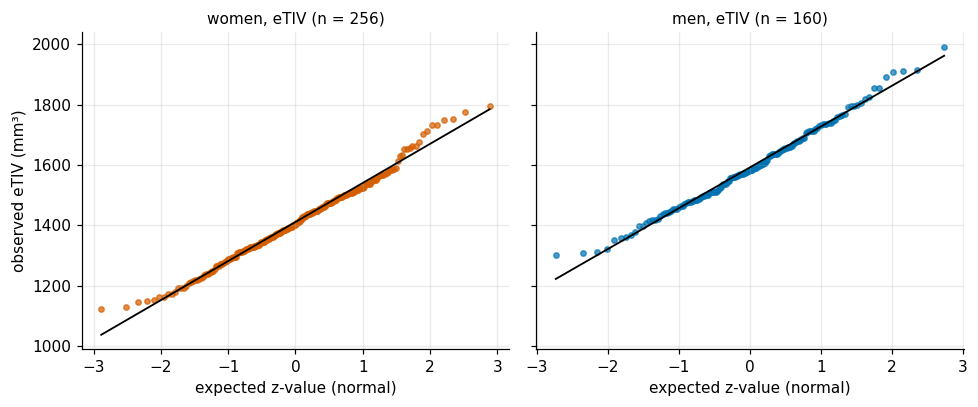

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
qq_plot(women_etiv, axes[0], f"women, eTIV (n = {len(women_etiv)})", C2)
qq_plot(men_etiv,   axes[1], f"men, eTIV (n = {len(men_etiv)})", C1)
axes[0].set_ylabel("observed eTIV (mm³)")
plt.tight_layout()
plt.show()

In both groups the bulk of the points lies right on the line; only a few extreme values at the ends drift off it (the women's upper tail runs a bit above the line, the men's lowest values lie below it). Tails are where single extreme values have the most influence. Judged by eye, `eTIV` is approximately normal **within each sex**.

**A common trap: pool the groups first.** If we ignore the sex and look at all participants together, the data are a *mixture* of two normal distributions with different means. For comparison, we also look at `nWBV` (normalized brain volume), which declines with age:

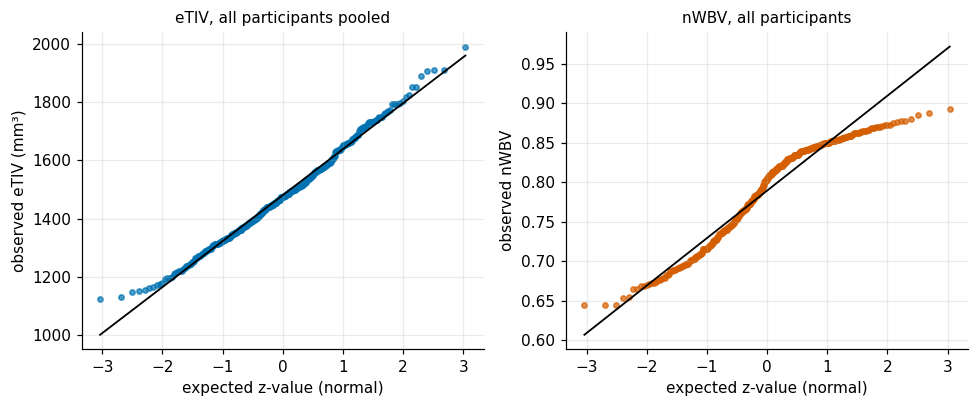

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
qq_plot(etiv_all, axes[0], "eTIV, all participants pooled")
axes[0].set_ylabel("observed eTIV (mm³)")
nwbv_all = df["nWBV"].dropna().to_numpy(float)
qq_plot(nwbv_all, axes[1], "nWBV, all participants", C2)
axes[1].set_ylabel("observed nWBV")
plt.tight_layout()
plt.show()

Pooled `eTIV` looks a little worse in the tails than within each sex, but the mixture effect is subtle here, because the two group means are only about 1.4 SDs apart. `nWBV` is clearly different: the points bend in an **S-shape** around the line (a compressed upper end, with many participants piled up at high values, and a steeper middle). The lesson for the t-test: **check normality within each group**, not for the pooled data, and read the *shape* of the deviation off the Q-Q plot.

### 4.2 Quantitative tests of normality

Eyeballing a plot is subjective, so we add formal tests. They all have the same logic, and it is *reversed* compared with what you may expect:

* **H0: the data come from a normal distribution.**
* A **small** p-value (< .05) is evidence **against** normality.
* A **large** p-value only means "no evidence against normality". It does **not** prove that the data are normal.

| Test | Idea |
|---|---|
| **Shapiro-Wilk** | how well do the sorted data correlate with the expected normal values (basically the Q-Q plot as one number)? Very good power; limited to n ≤ 5000 for the p-value |
| **D'Agostino-Pearson** (`normaltest`) | combines skewness and kurtosis into one statistic; needs n ≥ 8 |
| **Anderson-Darling** | compares the empirical and the normal cumulative distribution, with extra weight on the **tails** |

In [40]:
def anderson_p(x):
    """Anderson-Darling for normality; returns (A², p). Newer SciPy gives a p-value directly."""
    try:
        r = stats.anderson(x, dist="norm", method="interpolate")
        return r.statistic, r.pvalue
    except TypeError:                                  # older SciPy: only critical values
        r = stats.anderson(x, dist="norm")
        crit5 = r.critical_values[list(r.significance_level).index(5.0)]
        return r.statistic, f"A² {'>' if r.statistic > crit5 else '<'} {crit5:.3f} (5% critical value)"

def normality_table(groups):
    rows = []
    for name, x in groups.items():
        sw = stats.shapiro(x)
        dp = stats.normaltest(x)
        a2, ap = anderson_p(x)
        rows.append({"data": name, "n": len(x),
                     "Shapiro-Wilk p": sw.pvalue, "D'Agostino-Pearson p": dp.pvalue,
                     "Anderson-Darling A²": a2, "Anderson-Darling p": ap})
    return pd.DataFrame(rows).set_index("data")

groups = {"eTIV, women": women_etiv, "eTIV, men": men_etiv,
          "eTIV, pooled": etiv_all, "Age, women": women_age, "Age, men": men_age,
          "nWBV, all": nwbv_all}
normality_table(groups).round(4)

,n,Shapiro-Wilk p,D'Agostino-Pearson p,Anderson-Darling A²,Anderson-Darling p
data,,,,,
"eTIV, women",256,0.0523,0.1183,0.4431,A² < 0.775 (5% critical value)
"eTIV, men",160,0.4424,0.3221,0.2999,A² < 0.769 (5% critical value)
"eTIV, pooled",416,0.0246,0.0455,0.7592,A² < 0.780 (5% critical value)
"Age, women",256,0.0000,0.0000,10.5328,A² > 0.775 (5% critical value)
"Age, men",160,0.0000,0.0000,8.0594,A² > 0.769 (5% critical value)
"nWBV, all",416,0.0000,0.0000,8.8434,A² > 0.780 (5% critical value)


How to read the table (p < .05 means: reject normality):

* **`eTIV` within each sex:** no test rejects normality at .05 for the men; for the women the Shapiro-Wilk p-value is only just above .05 (borderline), the other two are clearly above. This roughly agrees with the Q-Q plots: close to normal, with minor wobbles.
* **`eTIV` pooled:** all three tests now reject at .05, though only narrowly. This is the mixture of two groups with different means.
* **`Age`:** clearly rejected in both sexes. The age distribution of this sample is far from a bell shape.
* **`nWBV`:** strongly rejected, matching the deviation we saw in the Q-Q plot.

### 4.3 The catch: tests depend on the sample size

Formal tests are not a replacement for the plot, because their **power depends on n**: with huge samples they reject normality for tiny, practically irrelevant deviations; with tiny samples they cannot detect even severe ones. We check this with data that are *slightly* non-normal (a t-distribution with 10 df, which is almost normal, but has slightly heavier tails):

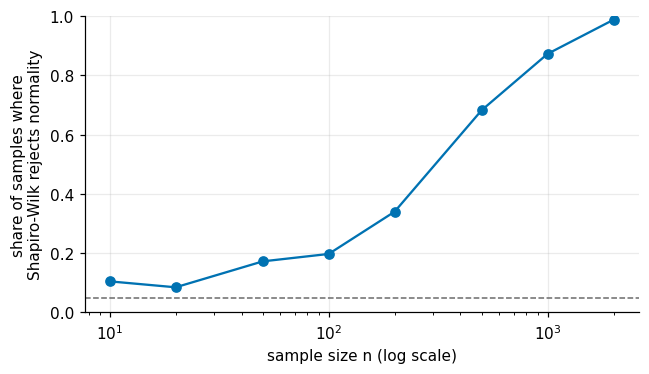

In [41]:
sizes = [10, 20, 50, 100, 200, 500, 1000, 2000]
reps = 400
reject = []
for n_ in sizes:
    rej = 0
    for _ in range(reps):
        x_ = rng.standard_t(10, n_)
        rej += stats.shapiro(x_).pvalue < .05
    reject.append(rej / reps)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(sizes, reject, "o-", color=C1)
ax.axhline(.05, color=GREY, ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("sample size n (log scale)")
ax.set_ylabel("share of samples where\nShapiro-Wilk rejects normality")
ax.set_ylim(0, 1)
plt.show()

The dashed line is the 5% we would see if the data were truly normal. For a distribution that is *almost* normal, the share of rejections climbs as n grows. A rejection with n = 2000 therefore does not necessarily mean the t-test is in trouble.

**Practical rule:** use the **plot and the test together**. The Q-Q plot tells you *what* kind of deviation there is and whether it is large; the test tells you whether the deviation is more than chance. For moderate to large groups the t-test is fairly robust against mild non-normality (because of the central limit theorem from last week). With small groups and a clear deviation, use a non-parametric test (session 9).

### 4.4 Equal variances: Levene's test

For the independent t-test the group variances should be about equal. **Levene's test** has H0: *the variances are equal* (again: small p = problem). If the variances are unequal, use the **Welch** test (`equal_var=False`), which does not need that assumption.

In [42]:
for name, a, b in [("eTIV", men_etiv, women_etiv), ("Age", men_age, women_age)]:
    lev = stats.levene(a, b)                      # SciPy default: centred at the median (Brown-Forsythe)
    print(f"{name}: SD men = {a.std(ddof=1):.1f}, SD women = {b.std(ddof=1):.1f}, "
          f"Levene W = {lev.statistic:.2f}, p = {lev.pvalue:.3f}")

eTIV: SD men = 135.2, SD women = 129.4, Levene W = 0.39, p = 0.533
Age: SD men = 25.1, SD women = 24.9, Levene W = 0.74, p = 0.392


Where Levene's p is large, the classic and Welch tests give nearly the same answer, as we saw in 3.1. Many people simply always use Welch, since it costs almost nothing when the variances happen to be equal.

## 5. Statistical power

**Power = 1 − β** is the probability that the test finds an effect that really exists. It depends on four things (change one, and the others move):

| Factor | Higher power if... |
|---|---|
| **effect size** | the true difference is larger (relative to the SD) |
| **sample size** | n is larger |
| **α** | α is larger (but then more false alarms) |
| **directed H1** | the test is one-sided (and the direction is right) |

Power is computed from the **non-central t distribution**: if H1 is true, the t statistic is not centred at 0, but at the non-centrality parameter δ = d · √(n₁n₂/(n₁+n₂)).

In [43]:
def power_t(d, n1, n2=None, alpha=.05, alternative="two-sided"):
    n2 = n1 if n2 is None else n2
    dof = n1 + n2 - 2
    nc = d * np.sqrt(n1 * n2 / (n1 + n2))
    if alternative == "two-sided":
        tc = stats.t.ppf(1 - alpha / 2, dof)
        p = stats.nct.sf(tc, dof, nc) + stats.nct.cdf(-tc, dof, nc)
    else:
        tc = stats.t.ppf(1 - alpha, dof)
        p = stats.nct.sf(tc, dof, nc)
    return 1.0 if np.isnan(p) else p      # scipy returns nan for huge non-centrality: power is ~1

def n_needed(d, power=.8, alpha=.05, alternative="two-sided"):
    n = 2
    while power_t(d, n, alpha=alpha, alternative=alternative) < power:
        n += 1
    return n

# check against the simulation from section 1: d = 0.5, n = 30 per group
print(f"formula: {power_t(.5, 30):.3f}   simulation: {power_rate:.3f}")

formula: 0.478   simulation: 0.486


The formula and the simulation agree (the small difference is simulation noise), so we can use the formula to answer the practical question: *how many participants per group do I need?* (a priori power analysis, done **before** the study). Convention: power = 80%, α = .05.

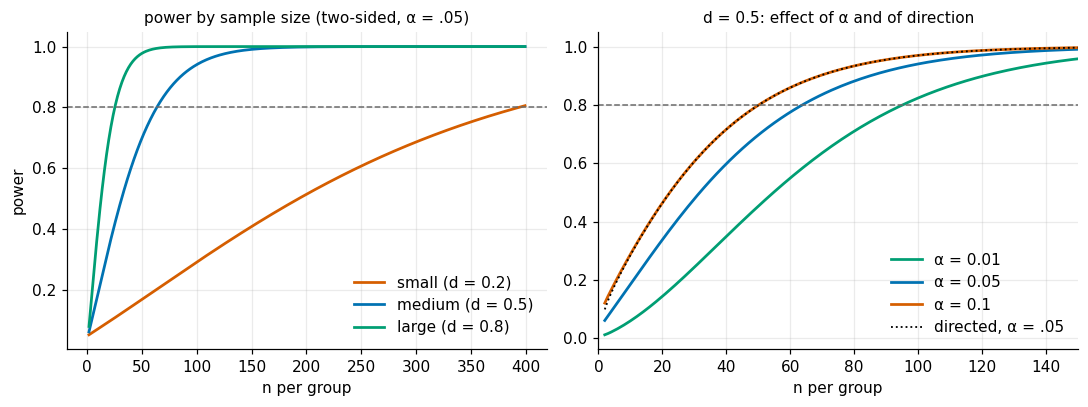

,n per group (two-sided),n per group (directed)
small (d = 0.2),394,310
medium (d = 0.5),64,51
large (d = 0.8),26,21


In [44]:
effects = {"small (d = 0.2)": .2, "medium (d = 0.5)": .5, "large (d = 0.8)": .8}
ns = np.arange(2, 400)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for (lab, d), col in zip(effects.items(), [C2, C1, "#009E73"]):
    axes[0].plot(ns, [power_t(d, n) for n in ns], color=col, lw=1.8, label=lab)
axes[0].axhline(.8, color=GREY, ls="--", lw=1)
axes[0].set_xlabel("n per group")
axes[0].set_ylabel("power")
axes[0].legend(frameon=False)
axes[0].set_title("power by sample size (two-sided, α = .05)", fontsize=10)

alphas = [.01, .05, .10]
for a_, col in zip(alphas, ["#009E73", C1, C2]):
    axes[1].plot(ns, [power_t(.5, n, alpha=a_) for n in ns], color=col, lw=1.8, label=f"α = {a_}")
axes[1].plot(ns, [power_t(.5, n, alternative="greater") for n in ns], color="black", lw=1.2, ls=":", label="directed, α = .05")
axes[1].axhline(.8, color=GREY, ls="--", lw=1)
axes[1].set_xlim(0, 150)
axes[1].set_xlabel("n per group")
axes[1].set_title("d = 0.5: effect of α and of direction", fontsize=10)
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

need = pd.DataFrame({"n per group (two-sided)": [n_needed(d) for d in effects.values()],
                     "n per group (directed)":   [n_needed(d, alternative="greater") for d in effects.values()]},
                    index=list(effects))
need

(In the right panel, the directed test at α = .05 follows the α = .10 curve almost exactly: the one-sided critical value is the same.) Small effects need *many* more participants than large ones (roughly a factor of 6 from d = 0.5 down to d = 0.2, since n grows with 1/d²).

### 5.1 Power in our data

For our two running examples we can take the **observed** effect and ask how many participants per group would have been sufficient. (Using the observed effect from the same sample is called *post hoc* power. It is only a rough guide, because the observed effect is itself uncertain, and the proper use of power analysis is *before* the study.)

In [45]:
d_etiv = (men_etiv.mean() - women_etiv.mean()) / pooled_sd(men_etiv, women_etiv)
d_age  = (men_age.mean()  - women_age.mean())  / pooled_sd(men_age, women_age)

pd.DataFrame({"observed |d|": [abs(d_etiv), abs(d_age)],
              "power with the real n": [power_t(abs(d_etiv), len(men_etiv), len(women_etiv)),
                                        power_t(abs(d_age),  len(men_age),  len(women_age))],
              "n per group needed (80%)": [n_needed(abs(d_etiv)), n_needed(abs(d_age))]},
             index=["eTIV, men vs. women", "Age, men vs. women"]).round(3)

,observed |d|,power with the real n,n per group needed (80%)
"eTIV, men vs. women",1.375,1.000,10
"Age, men vs. women",0.220,0.585,326


For `eTIV` (large effect) very few participants would already be enough; the study has power of practically 1. For the small age difference the sample is considerably underpowered, which is one more reason why a non-significant result must not be read as "there is no difference".

## 6. Effect sizes

### 6.1 Why a p-value is not enough

The p-value mixes two things: **how big the effect is** and **how large the sample is**. A fixed, tiny effect becomes "significant" if n is large enough. We show this by drawing samples of increasing size (300 repetitions each, median shown) from a population with a **true difference of d = 0.1** (a very small effect):

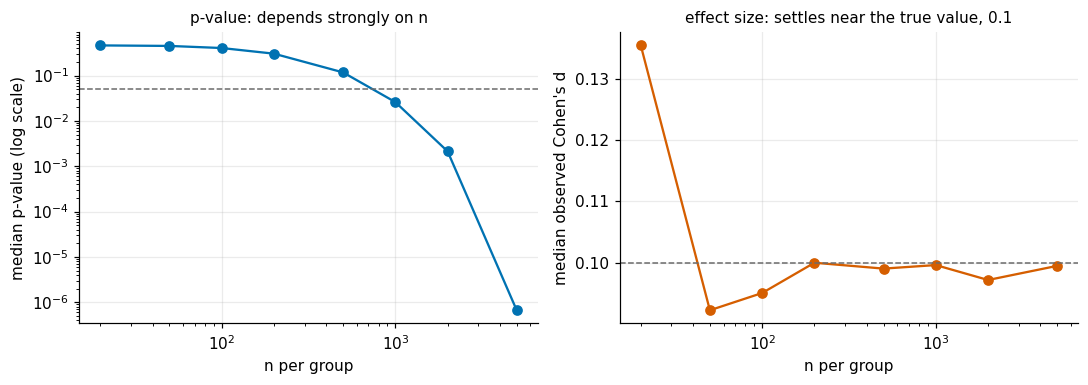

In [46]:
sizes = [20, 50, 100, 200, 500, 1000, 2000, 5000]
ps, ds = [], []
for n_ in sizes:
    a = rng.normal(0, 1, (300, n_))              # 300 repeated experiments per sample size,
    b = rng.normal(0.1, 1, (300, n_))            # so single lucky/unlucky draws do not dominate
    ps.append(np.median(stats.ttest_ind(a, b, axis=1).pvalue))
    ds.append(np.median((b.mean(1) - a.mean(1)) / np.sqrt((a.var(1, ddof=1) + b.var(1, ddof=1)) / 2)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(sizes, ps, "o-", color=C1)
axes[0].axhline(.05, color=GREY, ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("n per group"); axes[0].set_ylabel("median p-value (log scale)")
axes[0].set_title("p-value: depends strongly on n", fontsize=10)
axes[1].plot(sizes, ds, "o-", color=C2)
axes[1].axhline(.1, color=GREY, ls="--", lw=1)
axes[1].set_xscale("log")
axes[1].set_xlabel("n per group"); axes[1].set_ylabel("median observed Cohen's d")
axes[1].set_title("effect size: settles near the true value, 0.1", fontsize=10)
plt.tight_layout()
plt.show()

The p-value (left) drops with n, and the dashed line marks .05. The effect size (right) does not drop; it only becomes more *precise* and settles at the true value. So: **always report an effect size next to the p-value.**

### 6.2 Cohen's d

Cohen's d is the difference of the means in units of the pooled standard deviation:

$$d = \frac{\bar x_1 - \bar x_2}{s_{pooled}}$$

Conventional benchmarks: **0.2 small, 0.5 medium, 0.8 large** (rough guides, not laws; what counts as big depends on the field).

eTIV, men vs. women: d = 1.38
Age,  men vs. women: d = -0.22


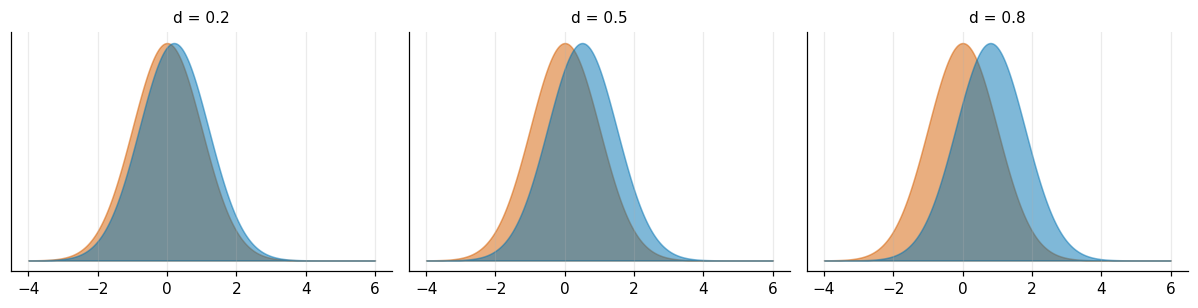

In [47]:
def cohens_d(a, b):
    return (np.mean(a) - np.mean(b)) / pooled_sd(np.asarray(a), np.asarray(b))

print(f"eTIV, men vs. women: d = {cohens_d(men_etiv, women_etiv):.2f}")
print(f"Age,  men vs. women: d = {cohens_d(men_age, women_age):.2f}")

# What does d mean? Two normal curves that are d SDs apart
x = np.linspace(-4, 6, 400)
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9), sharey=True)
for ax, d in zip(axes, [.2, .5, .8]):
    ax.fill_between(x, stats.norm.pdf(x), color=C2, alpha=.5)
    ax.fill_between(x, stats.norm.pdf(x, d), color=C1, alpha=.5)
    ax.set_title(f"d = {d}", fontsize=10)
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Reading these numbers: for `eTIV` the sex difference is roughly in the *large* range (the two curves have little overlap), while for `Age` it is *small* (almost completely overlapping curves). The same data thus answer two different questions: *is there an effect?* (p-value) and *how big is it?* (d).

### 6.3 Variance explained: η² and ω² (a preview of ANOVA)

Another way to express the effect is as the **share of the variance** of the dependent variable that is explained by group membership:

$$\eta^2 = \frac{t^2}{t^2 + df} \qquad\qquad \omega^2 = \frac{t^2 - 1}{t^2 + n_1 + n_2 - 1}$$

η² is biased upwards in small samples; ω² corrects for this. We will meet both again in the ANOVA sessions.

In [48]:
def eta_omega(a, b):
    r = stats.ttest_ind(a, b)
    t_, dof = r.statistic, len(a) + len(b) - 2
    eta2 = t_**2 / (t_**2 + dof)
    omega2 = (t_**2 - 1) / (t_**2 + len(a) + len(b) - 1)
    return eta2, omega2

rows = []
for name, a, b in [("eTIV", men_etiv, women_etiv), ("Age", men_age, women_age)]:
    e, o = eta_omega(a, b)
    rows.append({"variable": name, "Cohen's d": cohens_d(a, b), "η²": e, "ω²": o})
pd.DataFrame(rows).set_index("variable").round(3)

,Cohen's d,η²,ω²
variable,,,
eTIV,1.375,0.310,0.308
Age,-0.220,0.011,0.009


For `eTIV`, sex explains a substantial share of the variance; for `Age`, almost nothing.

Also note the relation between the numbers: d, η² and t all carry the same information about the group difference, just on different scales.

## 7. Reporting, and the word "significant"

A complete report of a t-test contains: the test used (and whether Welch), t, df, the p-value, the group means and SDs, **and an effect size** (with a confidence interval, if possible). For example, in the format used by many journals:

> Men (M = …, SD = …) had a larger eTIV than women (M = …, SD = …), t(df) = …, p < .001, d = ….

The code below assembles such a sentence from the results, so that no number is copied by hand.

In [49]:
def report(name, a, b, la="men", lb="women", unit=""):
    r = stats.ttest_ind(a, b, equal_var=False)
    p_txt = "p < .001" if r.pvalue < .001 else f"p = {r.pvalue:.3f}".replace("0.", ".")
    return (f"{name}: {la} (M = {a.mean():.1f}, SD = {a.std(ddof=1):.1f}) vs. {lb} "
            f"(M = {b.mean():.1f}, SD = {b.std(ddof=1):.1f}), Welch t({r.df:.1f}) = {r.statistic:.2f}, "
            f"{p_txt}, d = {cohens_d(a, b):.2f}")

print(report("eTIV", men_etiv, women_etiv))
print(report("Age",  men_age,  women_age))

eTIV: men (M = 1592.0, SD = 135.2) vs. women (M = 1410.9, SD = 129.4), Welch t(326.5) = 13.51, p < .001, d = 1.38
Age: men (M = 49.3, SD = 25.1) vs. women (M = 54.8, SD = 24.9), Welch t(336.0) = -2.18, p = .030, d = -0.22


**A caution about "significant":**

* *Statistically* significant means only "p < α". It says nothing about whether the effect is **important**; that is what the effect size is for (6.1).
* *Not significant* does not mean "no effect": it can also mean "too little power" (section 5).
* The line at .05 is a convention. p = .049 and p = .051 are practically the same evidence.
* If you run many tests, some will be significant by chance (α is a *per-test* error rate). This returns when we compare several groups at once (ANOVA).

## 8. Summary

* A test asks how surprising the data are **if H0 were true**. The **p-value** is that probability; α is the false alarm rate we accept; β is the miss rate; **power = 1 − β**.
* **t = difference / standard error**, compared with a t distribution with the matching df. A directed H1 uses one tail and is decided **before** the data.
* **Independent**, **dependent** (a one-sample test on the differences) and **single group** t-tests answer different design questions; use the one that matches how the data were collected.
* Check the assumptions **within each group**: Q-Q plot first (what kind of deviation?), then the formal tests (Shapiro-Wilk, D'Agostino-Pearson, Anderson-Darling; H0 = "normal") with their sample-size caveat, and Levene for equal variances (or just use Welch).
* Plan the sample size with a **power analysis** (a priori); small effects need many participants.
* **Always report an effect size** (Cohen's d, η², ω²) next to the p-value: the p-value depends on n, the effect size does not.

### Sources

* Slides: `04_t-TestEffectSizes.pptx` (course material).
* Data: Marcus, D. S., Wang, T. H., Parker, J., Csernansky, J. G., Morris, J. C., & Buckner, R. L. (2007). Open Access Series of Imaging Studies (OASIS): Cross-sectional MRI data in young, middle aged, nondemented, and demented older adults. *Journal of Cognitive Neuroscience, 19*(9), 1498-1507.
* SciPy documentation: `scipy.stats` (`ttest_ind`, `ttest_rel`, `ttest_1samp`, `shapiro`, `normaltest`, `anderson`, `levene`, `nct`).